<a href="https://colab.research.google.com/github/DinaraAntropova/MachineLearning_2/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%BD%D0%B0_3_%D0%9C%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%B5_%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D0%92%D0%B0%D1%80%D1%96%D0%B0%D0%BD%D1%82_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Завантаження датасету
uploaded = files.upload()

# Зчитування CSV-файлу
df = pd.read_csv("bank-full.csv", sep=";")

# Перевірка розміру датасету
print("Розмір датасету:", df.shape)

# Виведення перших п'яти записів
print("\nПерші 5 рядків:")
display(df.head())

# Перевірка пропущених значень
print("\nКількість пропущених значень:")
print(df.isnull().sum().sum())


Saving bank-full.csv to bank-full.csv
Розмір датасету: (45211, 17)

Перші 5 рядків:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Кількість пропущених значень:
0


In [2]:

from sklearn.model_selection import train_test_split

# Створення копії датасету
data = df.copy()

# Перетворення цільової змінної
data["y"] = data["y"].map({"no": 0, "yes": 1})

# Вхідні ознаки
X = data.drop(columns=["y", "duration"])

# Цільова змінна
y = data["y"]

# Розділення на навчальну і тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

print("\nКількість класів у навчальній вибірці:")
print(y_train.value_counts())

print("\nКількість класів у тестовій вибірці:")
print(y_test.value_counts())


Навчальна вибірка: (36168, 15)
Тестова вибірка: (9043, 15)

Кількість класів у навчальній вибірці:
y
0    31937
1     4231
Name: count, dtype: int64

Кількість класів у тестовій вибірці:
y
0    7985
1    1058
Name: count, dtype: int64


In [3]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Визначаємо категоріальні та числові ознаки
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Створюємо перетворювач даних
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

# Підготовка навчальних даних
X_train_encoded = preprocessor.fit_transform(X_train)

# Підготовка тестових даних
X_test_encoded = preprocessor.transform(X_test)

# Перевірка результатів
print("Категоріальні ознаки:", len(categorical_cols))
print("Числові ознаки:", len(numeric_cols))

print("\nНавчальна вибірка:", X_train_encoded.shape)
print("Тестова вибірка:", X_test_encoded.shape)

print("\nПідготовка даних завершена!")


Категоріальні ознаки: 9
Числові ознаки: 6

Навчальна вибірка: (36168, 50)
Тестова вибірка: (9043, 50)

Підготовка даних завершена!


In [4]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Створюємо три моделі класифікації
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

# Навчання та оцінювання моделей
metrics_rows = []
model_predictions = {}

for name, model in models.items():

    print(f"Навчання моделі: {name}")

    # Навчання
    model.fit(X_train_encoded, y_train)

    # Прогнозування
    y_pred = model.predict(X_test_encoded)
    model_predictions[name] = y_pred

    # Збереження метрик
    metrics_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

# Таблиця порівняння
results_base = pd.DataFrame(metrics_rows)

print("\nРезультати навчання моделей:")
display(results_base.round(3))


Навчання моделі: Logistic Regression
Навчання моделі: Decision Tree
Навчання моделі: Random Forest

Результати навчання моделей:


,Модель,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.755,0.266,0.624,0.373
1,Decision Tree,0.829,0.357,0.579,0.442
2,Random Forest,0.821,0.349,0.612,0.444


In [5]:

from sklearn.ensemble import VotingClassifier

# Створення ансамблевої моделі
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("dt", models["Decision Tree"]),
        ("rf", models["Random Forest"])
    ],
    voting="hard"
)

# Навчання ансамблю
voting_model.fit(X_train_encoded, y_train)

# Прогнозування на тестових даних
y_pred_voting = voting_model.predict(X_test_encoded)

# Оцінка якості
voting_results = pd.DataFrame([{
    "Модель": "Voting Classifier",
    "Accuracy": accuracy_score(y_test, y_pred_voting),
    "Precision": precision_score(
        y_test, y_pred_voting, zero_division=0
    ),
    "Recall": recall_score(y_test, y_pred_voting),
    "F1-score": f1_score(y_test, y_pred_voting)
}])

print("Результати ансамблевої моделі:")
display(voting_results.round(3))

# Об'єднання результатів усіх моделей
results_all = pd.concat(
    [results_base, voting_results],
    ignore_index=True
)

print("\nПорівняння всіх моделей:")
display(results_all.round(3))


Результати ансамблевої моделі:


,Модель,Accuracy,Precision,Recall,F1-score
0,Voting Classifier,0.824,0.353,0.604,0.446



Порівняння всіх моделей:


,Модель,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.755,0.266,0.624,0.373
1,Decision Tree,0.829,0.357,0.579,0.442
2,Random Forest,0.821,0.349,0.612,0.444
3,Voting Classifier,0.824,0.353,0.604,0.446


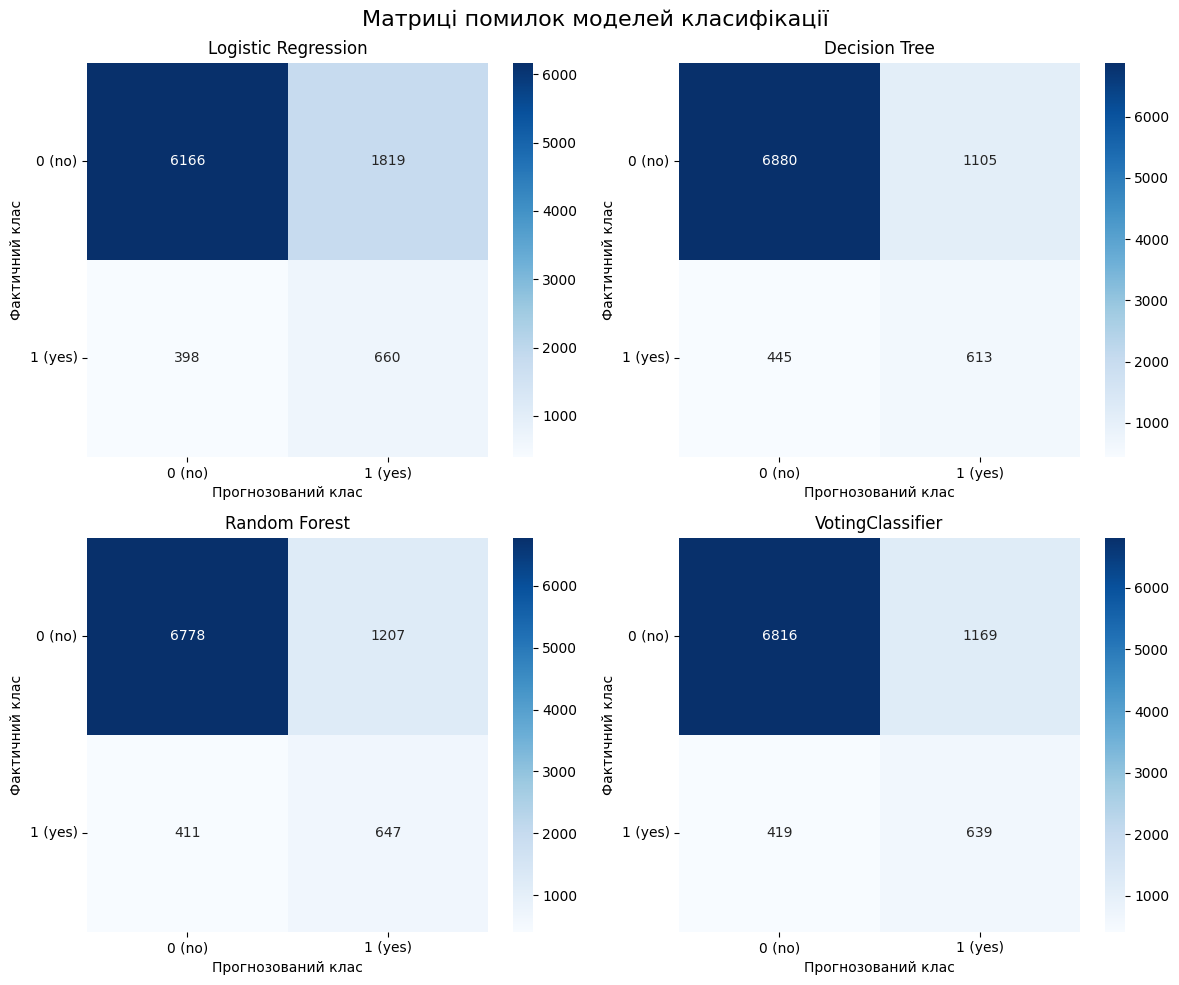

In [6]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Прогнози всіх моделей
predictions = {
    "Logistic Regression": model_predictions["Logistic Regression"],
    "Decision Tree": model_predictions["Decision Tree"],
    "Random Forest": model_predictions["Random Forest"],
    "VotingClassifier": y_pred_voting
}

# Створюємо чотири матриці помилок
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Фактичний клас")

    ax.set_xticklabels(["0 (no)", "1 (yes)"])
    ax.set_yticklabels(["0 (no)", "1 (yes)"], rotation=0)

plt.suptitle(
    "Матриці помилок моделей класифікації",
    fontsize=16
)

plt.tight_layout()

# Зберігаємо графік для звіту
plt.savefig(
    "confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


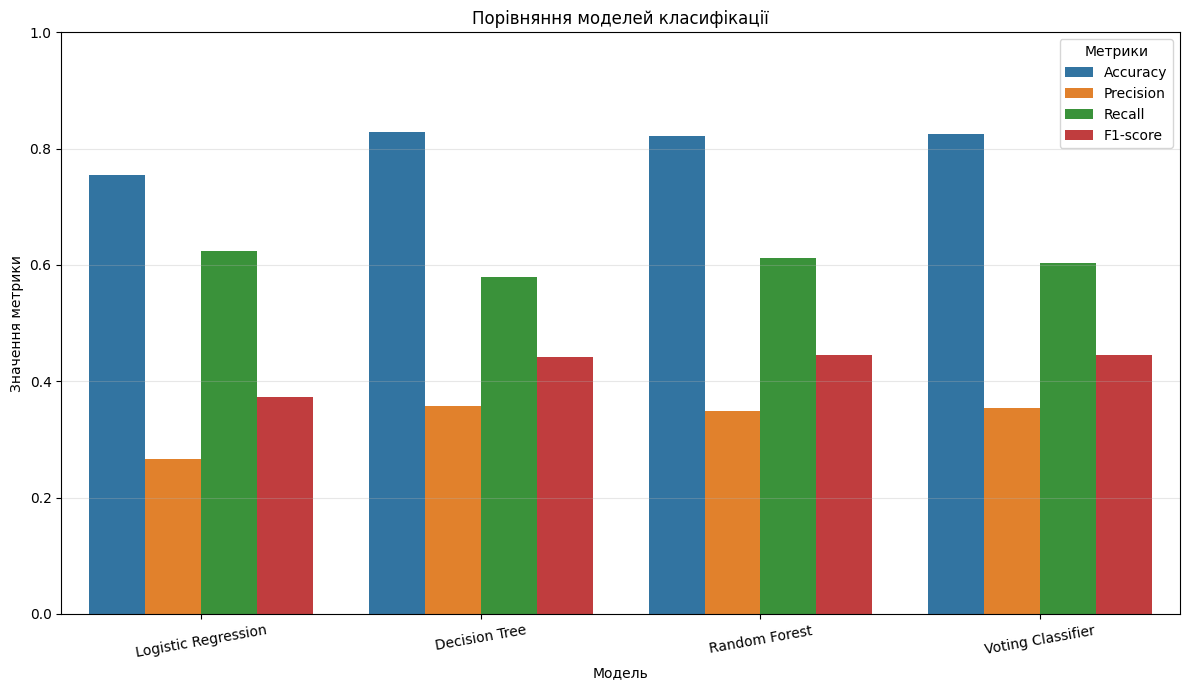

In [7]:

# Порівняння всіх моделей класифікації

# Перетворюємо таблицю для побудови графіка
results_plot = results_all.melt(
    id_vars="Модель",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Метрика",
    value_name="Значення"
)

# Створюємо графік
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_plot,
    x="Модель",
    y="Значення",
    hue="Метрика"
)

plt.title("Порівняння моделей класифікації")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1)

plt.legend(title="Метрики")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=10)

plt.tight_layout()

# Збереження графіка для звіту
plt.savefig(
    "models_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
